# Chicago Taxi Trips — Week of 11–17 September 2023

Descriptive summary of **reported** taxi trips (not total market volume) for Monday 11 to Sunday 17 September 2023. After cleaning, the analysis uses **135,132 trips and $4.02M of `trip_total` revenue**. Details of the 636 excluded rows (0.47%) are in section 2.

**Summary**

- **When (Q1):** Demand is a weekday pattern. Mon–Thu average about 22,300 trips a day (Wednesday busiest, 22,601), Friday is lower (20,137) and weekend days are about 59% of a weekday (Saturday quietest, 12,635). Weekdays peak at 17:00 and stay high from 09:00 to 18:59, and every day is quietest at 02:00–04:00. Weekends are flatter and busier than weekdays after midnight.
- **Where (Q2):** Trips start in a few places. The top 10 pickup community areas carry 85% of trips and 86% of revenue. Area 76 leads on both (23% of trips, 43% of revenue). Areas 8 and 32 are next on trips. 2.8% of trips (3,736) have no pickup community area.
- **Payment and tips (Q3):** Credit Card is 44.5% of trips and 59.6% of revenue; Cash is 29.3% of trips and 19.5% of revenue. Only Credit Card and Mobile record tips reliably, and there tips are about 22% and 20% of fare. Cash, Prcard and Unknown record almost none, so they can't be compared.
- **Companies (Q4):** Flash Cab (19.2% of trips) and Taxi Affiliation Services (19.0%) are effectively tied for first. The top 10 companies carry 92% of trips, using 2,414 distinct taxis between them.

# ## 1. Data loading
#
# All figures describe **reported** trips (the City notes that not every trip is reported), not total market volume.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

os.makedirs("figures/analysis", exist_ok=True)

# Chart styling: one blue for magnitude, orange to flag weekends, muted grey for context
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a95"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelsize": 10.5,
})

raw = pd.read_csv("trips.csv", dtype={"pickup_census_tract": "string", "dropoff_census_tract": "string"})
print("shape:", raw.shape)
print()
print(raw.dtypes)

shape: (135768, 23)

trip_id                           str
taxi_id                           str
trip_start_timestamp              str
trip_end_timestamp                str
trip_seconds                  float64
trip_miles                    float64
pickup_census_tract            string
dropoff_census_tract           string
pickup_community_area         float64
dropoff_community_area        float64
fare                          float64
tips                          float64
tolls                         float64
extras                        float64
trip_total                    float64
payment_type                      str
company                           str
pickup_centroid_latitude      float64
pickup_centroid_longitude     float64
pickup_centroid_location          str
dropoff_centroid_latitude     float64
dropoff_centroid_longitude    float64
dropoff_centroid_location         str
dtype: object


In [2]:
# Missing values per column, and uniqueness of trip_id
miss = raw.isna().sum().to_frame("n_missing")
miss["pct_missing"] = miss["n_missing"] / len(raw) * 100
print(miss[miss.n_missing > 0])
print()
print("duplicate trip_id:", raw.trip_id.duplicated().sum(), "| fully duplicated rows:", raw.duplicated().sum())
print("start range:", raw.trip_start_timestamp.min(), "->", raw.trip_start_timestamp.max())

                            n_missing  pct_missing
trip_end_timestamp                  1         0.00
trip_seconds                       33         0.02
pickup_census_tract             71404        52.59
dropoff_census_tract            73842        54.39
pickup_community_area            3815         2.81
dropoff_community_area          13794        10.16
fare                              324         0.24
tips                              324         0.24
tolls                             324         0.24
extras                            324         0.24
trip_total                        324         0.24
pickup_centroid_latitude         3775         2.78
pickup_centroid_longitude        3775         2.78
pickup_centroid_location         3775         2.78
dropoff_centroid_latitude       12872         9.48
dropoff_centroid_longitude      12872         9.48
dropoff_centroid_location       12872         9.48

duplicate trip_id: 0 | fully duplicated rows: 0
start range: 2023-09-11T00:00:00.

# ## 2. Data quality checks and cleaning
#
# First inspect, then decide. Nothing is dropped until the decisions are listed in the table at the end of this section.

In [3]:
df = raw.copy()
df["start"] = pd.to_datetime(df.trip_start_timestamp)
df["end"] = pd.to_datetime(df.trip_end_timestamp)

num = ["trip_seconds", "trip_miles", "fare", "tips", "tolls", "extras", "trip_total"]
q = df[num].describe(percentiles=[.01, .5, .99, .999]).T
print(q)
print()
print("Zero counts / negative counts:")
print(pd.DataFrame({"zero": (df[num] == 0).sum(), "negative": (df[num] < 0).sum()}))

                  count     mean      std  min   1%      50%      99%     99.9%       max
trip_seconds 135,735.00 1,346.54 1,762.25 0.00 0.00 1,020.00 4,872.98 12,416.09 86,160.00
trip_miles   135,768.00     6.94     7.85 0.00 0.00     3.24    27.14     44.08    792.90
fare         135,444.00    23.87    19.60 0.00 3.25    17.75    75.50    150.00    911.00
tips         135,444.00     3.38     4.67 0.00 0.00     2.00    17.10     33.33    130.00
tolls        135,444.00     0.13    20.42 0.00 0.00     0.00     0.00      5.00  4,444.44
extras       135,444.00     2.54    18.31 0.00 0.00     0.00    35.50     65.75  4,445.44
trip_total   135,444.00    30.12    43.93 0.00 3.25    21.25   104.43    186.53  8,901.13

Zero counts / negative counts:
                zero  negative
trip_seconds    2731         0
trip_miles     13993         0
fare             135         0
tips           60991         0
tolls         134709         0
extras         80677         0
trip_total       134         0


In [4]:
print(df.payment_type.value_counts(dropna=False))
print()
print(df.company.value_counts(dropna=False).head(25))
print("n companies:", df.company.nunique(), "| n taxis:", df.taxi_id.nunique(), "| taxi_id missing:", df.taxi_id.isna().sum())

payment_type
Credit Card    60291
Cash           40053
Mobile         18594
Prcard         11961
Unknown         4784
No Charge         54
Dispute           31
Name: count, dtype: int64

company
Flash Cab                               25950
Taxi Affiliation Services               25727
Sun Taxi                                15122
Taxicab Insurance Agency Llc            13914
City Service                            13747
Chicago Independents                     8004
5 Star Taxi                              6121
Medallion Leasin                         5003
Globe Taxi                               4772
Blue Ribbon Taxi Association             4390
Star North Taxi Management Llc           2815
Taxicab Insurance Agency, LLC            2379
Choice Taxi Association                  2022
Chicago City Taxi Association            1386
Choice Taxi Association Inc              1064
U Taxicab                                1048
Chicago Taxicab                           406
Patriot Taxi Dba Peace 

In [5]:
# Does trip_total equal fare + tips + tolls + extras?
parts = df[["fare", "tips", "tolls", "extras"]].sum(axis=1, min_count=4)
df["total_gap"] = df.trip_total - parts
g = df.total_gap.dropna()
print("rows with computable gap:", len(g))
print("exact match (|gap|<0.005):", (g.abs() < 0.005).sum(), f"({(g.abs() < 0.005).mean():.2%})")
print("gap quantiles:")
print(g.quantile([0, .001, .01, .05, .5, .95, .99, .999, 1]))
print()
print("Gap value counts (rounded to 0.01), top 12:")
print(g.round(2).value_counts().head(12))

rows with computable gap: 135444
exact match (|gap|<0.005): 87247 (64.42%)
gap quantiles:
0.00   -0.00
0.00   -0.00
0.01    0.00
0.05    0.00
0.50    0.00
0.95    0.50
0.99    2.50
1.00    3.00
1.00    3.00
Name: total_gap, dtype: float64

Gap value counts (rounded to 0.01), top 12:
total_gap
0.00    87247
0.50    46522
3.00      804
2.50      751
1.00      109
1.95        5
1.50        4
2.00        2
Name: count, dtype: int64


In [6]:
# Full company list (to find spelling variants) 
print(df.company.value_counts().iloc[20:].to_string())

company
312 Medallion Management Corp           273
Setare Inc                              119
Taxi Affiliation Services Llc - Yell     75
Metro Jet Taxi A.                        67
5167 - 71969 5167 Taxi Inc               53
6574 - Babylon Express Inc.              49
4623 - 27290 Jay Kim                     45
2733 - 74600 Benny Jona                  30
3556 - 36214 RC Andrews Cab              26
Petani Cab Corp                          25
4787 - 56058 Reny Cab Co                 16
4053 - 40193 Adwar H. Nikola             11


In [7]:
# What drives the unitemised gap?
df["gap_r"] = df.total_gap.round(2)
print(pd.crosstab(df.gap_r, df.payment_type))
print()
print("Gap by pickup-area-missing:")
print(pd.crosstab(df.gap_r, df.pickup_community_area.isna()))
print()
print("Gap 2.5/3.0 vs 0.5 by median miles:")
print(df.groupby("gap_r").trip_miles.agg(["count", "median", "mean"]))

payment_type   Cash  Credit Card  Dispute  Mobile  No Charge  Prcard  Unknown
gap_r                                                                        
0.00          39052        16962       31   14420         54   11944     4784
0.50              3        42409        0    4110          0       0        0
1.00              0          107        0       2          0       0        0
1.50              0            4        0       0          0       0        0
1.95              0            0        0       5          0       0        0
2.00              0            2        0       0          0       0        0
2.50            675            2        0      57          0      17        0
3.00              0          804        0       0          0       0        0

Gap by pickup-area-missing:
pickup_community_area  False  True 
gap_r                              
0.00                   84160   3087
0.50                   45827    695
1.00                      84     25
1.50       

In [8]:
# Extreme values: look at the rows
cols = ["start", "trip_seconds", "trip_miles", "fare", "tips", "tolls", "extras", "trip_total", "payment_type", "company"]
print("Top 8 by trip_total:")
print(df.nlargest(8, "trip_total")[cols].to_string())
print("\nTop 8 by trip_miles:")
print(df.nlargest(8, "trip_miles")[cols].to_string())
print("\nTop 8 by trip_seconds:")
print(df.nlargest(8, "trip_seconds")[cols].to_string())
print("\nTolls > 20:")
print(df[df.tolls > 20][cols].to_string())

Top 8 by trip_total:
                     start  trip_seconds  trip_miles   fare  tips    tolls   extras  trip_total payment_type                        company
124235 2023-09-16 19:00:00      1,080.00        0.10  11.25  0.00 4,444.44 4,445.44    8,901.13         Cash      Taxi Affiliation Services
25636  2023-09-16 13:45:00          0.00        0.00   3.25  0.00 4,444.44 4,444.44    8,892.13         Cash      Taxi Affiliation Services
35524  2023-09-12 20:15:00        420.00        1.30   6.75  0.00 4,111.10     0.44    4,118.29         Cash      Taxi Affiliation Services
127990 2023-09-14 14:00:00           NaN       37.45 911.00  0.00     0.00     0.00      911.00         Cash   Blue Ribbon Taxi Association
31648  2023-09-12 07:15:00          3.00        0.00 900.00  0.00     0.00     0.00      900.00         Cash                      Flash Cab
99632  2023-09-13 20:45:00         60.00        0.00 758.00  0.00     0.00     0.00      758.00    No Charge  Taxicab Insurance Agency, LLC

In [9]:
d = df
print("fare==0 rows:", (d.fare == 0).sum(), "| payment types:", d.loc[d.fare == 0, "payment_type"].value_counts().to_dict())
print("fare between 0 and 3.25 (exclusive):", ((d.fare > 0) & (d.fare < 3.25)).sum())
print()
z = d[d.trip_seconds == 0]
print("trip_seconds==0:", len(z), "| of which miles==0:", (z.trip_miles == 0).sum(), "| fare median:", z.fare.median(), "| fare>10:", (z.fare > 10).sum())
print("trip_seconds NaN:", d.trip_seconds.isna().sum(), "| of which trip_total NaN:", (d.trip_seconds.isna() & d.trip_total.isna()).sum())
m0 = d[(d.trip_miles == 0) & (d.trip_seconds > 0)]
print("miles==0 & seconds>0:", len(m0), "| fare median:", m0.fare.median(), "| seconds median:", m0.trip_seconds.median())
print("miles==0 & seconds>0 & seconds>300:", (m0.trip_seconds > 300).sum(), "| fare>10:", (m0.fare > 10).sum())
print()
ok = d[(d.trip_seconds > 0) & (d.trip_miles > 0)].copy()
ok["mph"] = ok.trip_miles / (ok.trip_seconds / 3600)
ok["fare_per_mile"] = ok.fare / ok.trip_miles
print("speed mph quantiles (secs>0 & miles>0):")
print(ok.mph.quantile([.001, .01, .5, .99, .999, .9999]).round(1).to_dict())
print("n with mph > 80:", (ok.mph > 80).sum(), "| mph>100:", (ok.mph > 100).sum())
print("fare per mile quantiles:", ok.fare_per_mile.quantile([.01, .5, .99, .999]).round(2).to_dict())
print()
print("Distribution: fare thresholds")
for t in [100, 150, 200, 300]:
    print(f"  fare > {t}: {(d.fare > t).sum()}")
print("trip_seconds > 4h:", (d.trip_seconds > 4*3600).sum(), "| > 8h:", (d.trip_seconds > 8*3600).sum(), "| > 12h:", (d.trip_seconds > 12*3600).sum())
print("trip_miles > 100:", (d.trip_miles > 100).sum(), "| >60:", (d.trip_miles > 60).sum())

fare==0 rows: 135 | payment types: {'Cash': 131, 'Credit Card': 2, 'No Charge': 1, 'Unknown': 1}
fare between 0 and 3.25 (exclusive): 36

trip_seconds==0: 2731 | of which miles==0: 2637 | fare median: 3.25 | fare>10: 575
trip_seconds NaN: 33 | of which trip_total NaN: 8
miles==0 & seconds>0: 11344 | fare median: 9.5 | seconds median: 300.0
miles==0 & seconds>0 & seconds>300: 5597 | fare>10: 5212

speed mph quantiles (secs>0 & miles>0):
{0.001: 0.2, 0.01: 0.6, 0.5: 15.0, 0.99: 50.9, 0.999: 87.0, 0.9999: 3150.9}
n with mph > 80: 134 | mph>100: 108
fare per mile quantiles: {0.01: 2.39, 0.5: 3.46, 0.99: 115.38, 0.999: 2500.0}

Distribution: fare thresholds
  fare > 100: 388
  fare > 150: 114
  fare > 200: 49
  fare > 300: 26
trip_seconds > 4h: 121 | > 8h: 88 | > 12h: 61
trip_miles > 100: 11 | >60: 45


In [10]:
# Rows with high fare: are they plausible given miles/seconds?
cols = ["trip_seconds", "trip_miles", "fare", "tips", "tolls", "extras", "trip_total", "payment_type"]
hf = d[d.fare > 150].sort_values("fare", ascending=False)
print(len(hf))
print(hf[cols].head(40).to_string())

114
        trip_seconds  trip_miles   fare   tips  tolls  extras  trip_total payment_type
127990           NaN       37.45 911.00   0.00   0.00    0.00      911.00         Cash
31648           3.00        0.00 900.00   0.00   0.00    0.00      900.00         Cash
99632          60.00        0.00 758.00   0.00   0.00    0.00      758.00    No Charge
51799           0.00        0.00 550.00   0.00   0.00    0.00      550.00         Cash
30785           0.00        0.00 550.00   0.00   0.00    0.00      550.00  Credit Card
124119          0.00        0.00 500.00   0.00   0.00    0.00      500.00         Cash
52838      18,154.00      195.66 471.50   0.00   0.00    9.00      483.00  Credit Card
22094           0.00        0.00 450.06   0.00   0.00    0.00      450.06         Cash
81283           0.00        0.00 450.00   0.00   0.00    0.00      450.00         Cash
5186       15,011.00      194.81 445.50   0.00   0.00   24.50      472.50  Credit Card
88497          17.00        0.16 430.00

In [11]:
# Candidate rule: fare > $100 AND fare > 2.5x the fare implied by recorded miles (3.25 + 2.25/mile)
d = df
d["expected_fare"] = 3.25 + 2.25 * d.trip_miles
cand = (d.fare > 100) & (d.fare > 2.5 * d.expected_fare)
print("flagged:", cand.sum(), "| fare>100 total:", (d.fare > 100).sum(), "| fare>100 kept:", ((d.fare > 100) & ~cand).sum())
cols = ["trip_seconds", "trip_miles", "fare", "expected_fare", "tips", "trip_total", "payment_type"]
print("\nKept high-fare rows with the highest fare/expected ratio (sanity check on the boundary):")
kept = d[(d.fare > 100) & ~cand].assign(ratio=lambda x: x.fare / x.expected_fare).sort_values("ratio", ascending=False)
print(kept[cols + ["ratio"]].head(12).to_string())
print("\nFlagged rows with the lowest fare (boundary):")
print(d[cand].sort_values("fare")[cols].head(8).to_string())
print("\nFlagged: total fare $", d.loc[cand, "fare"].sum().round(0), "| median miles", d.loc[cand, "trip_miles"].median())

flagged: 174 | fare>100 total: 388 | fare>100 kept: 214

Kept high-fare rows with the highest fare/expected ratio (sanity check on the boundary):
        trip_seconds  trip_miles   fare  expected_fare  tips  trip_total payment_type  ratio
49296      18,222.00       26.26 152.25          62.34  0.00      158.25         Cash   2.44
65354      15,225.00       20.56 120.25          49.51  0.00      120.25         Cash   2.43
120819      2,954.00       20.52 120.00          49.42 24.20      145.20  Credit Card   2.43
120690     29,066.00       41.40 231.50          96.40  0.00      235.50         Cash   2.40
111853      2,009.00       23.79 136.07          56.78  0.00      136.07         Cash   2.40
81929       2,028.00       23.83 136.07          56.87  0.00      136.07         Cash   2.39
106115      2,052.00       27.63 155.43          65.42  0.00      155.43         Cash   2.38
84052       1,639.00       19.62 112.00          47.40 10.00      146.50  Credit Card   2.36
103540      5,193

In [12]:
# The 40-row gap: pickup area missing but centroid present
gap = d[d.pickup_community_area.isna() & d.pickup_centroid_latitude.notna()]
print(len(gap))
print(gap[["pickup_census_tract", "pickup_centroid_latitude", "pickup_centroid_longitude", "fare", "company"]].head(6).to_string())
print(gap.pickup_census_tract.notna().sum(), "of them have a census tract")

40
      pickup_census_tract  pickup_centroid_latitude  pickup_centroid_longitude  fare                       company
5285          17031770700                     41.98                     -87.88 25.00  Taxicab Insurance Agency Llc
5912          17031770700                     41.98                     -87.88  3.25                     Flash Cab
12033         17031770700                     41.98                     -87.88  3.25                     Flash Cab
13942         17031770700                     41.98                     -87.88 56.00          Chicago Independents
14433         17031770700                     41.98                     -87.88  3.25                   5 Star Taxi
25964         17031770700                     41.98                     -87.88  3.25                     Flash Cab
40 of them have a census tract


In [13]:
import re

# --- Company name harmonisation: merge spelling variants only (case, punctuation, Inc/LLC suffix) ---
def norm_company(s):
    t = re.sub(r"[.,]", "", str(s)).strip()
    t = re.sub(r"\s+(llc|inc)$", "", t, flags=re.I)
    return t.lower()

canon = (df.assign(_k=df.company.map(norm_company))
           .groupby("_k").company.agg(lambda s: s.value_counts().index[0]))   # most common spelling wins
df["company_clean"] = df.company.map(norm_company).map(canon)
variants = df.groupby("company_clean").company.nunique()
print("Merged spelling variants:")
for c in variants[variants > 1].index:
    print(f"  {c!r}  <-  {sorted(df.loc[df.company_clean == c, 'company'].unique())}")
print("companies before:", df.company.nunique(), "-> after:", df.company_clean.nunique())

# --- Exclusion waterfall (sequential, so each row is counted once) ---
rules = [
    ("E1  money fields missing (fare/tips/tolls/extras/trip_total all blank)", df.trip_total.isna()),
    ("E2  fare = 0 or trip_total = 0 (no usable charge)",                       (df.fare == 0) | (df.trip_total == 0)),
    ("E3  tolls > $100 (entry errors; largest plausible toll in data is $75)",  df.tolls > 100),
    ("E4  fare > $100 and > 2.5x fare implied by recorded miles (3.25+2.25/mi)", (df.fare > 100) & (df.fare > 2.5 * (3.25 + 2.25 * df.trip_miles))),
]
keep = pd.Series(True, index=df.index)
rows = [("Start (all rows in trips.csv)", 0, 0)]
for name, m in rules:
    hit = m & keep
    rows.append((name, int(hit.sum()), int(hit.sum())))
    keep &= ~m
wf = pd.DataFrame(rows, columns=["step", "rows_affected", "_"]).drop(columns="_")
wf["rows_remaining"] = len(df) - wf.rows_affected.cumsum()
print()
print(wf.to_string(index=False))

clean = df[keep].copy()
print()
print(f"clean rows: {len(clean):,}  (excluded {len(df)-len(clean):,} = {(len(df)-len(clean))/len(df):.2%})")
print(f"trip_total revenue before: ${df.trip_total.sum():,.0f} | after: ${clean.trip_total.sum():,.0f} | removed: ${df.trip_total.sum()-clean.trip_total.sum():,.0f}")

Merged spelling variants:
  'Choice Taxi Association'  <-  ['Choice Taxi Association', 'Choice Taxi Association Inc']
  'Taxicab Insurance Agency Llc'  <-  ['Taxicab Insurance Agency Llc', 'Taxicab Insurance Agency, LLC']
companies before: 32 -> after: 30

                                                                    step  rows_affected  rows_remaining
                                                                   Start         135768          135768
  E1  money fields missing (fare/tips/tolls/extras/trip_total all blank)            324          135444
                       E2  fare = 0 or trip_total = 0 (no usable charge)            135          135309
  E3  tolls > $100 (entry errors; largest plausible toll in data is $75)              3          135306
E4  fare > $100 and > 2.5x fare implied by recorded miles (3.25+2.25/mi)            174          135132

clean rows: 135,132  (excluded 636 = 0.47%)
trip_total revenue before: $4,079,349 | after: $4,021,016 | removed: $58,3

In [14]:
# Retained-but-flagged items, counted on the clean base
c = clean
n = len(c)
gap_c = (c.trip_total - c[["fare", "tips", "tolls", "extras"]].sum(axis=1)).round(2)
flags = pd.Series({
    "trip_seconds = 0": (c.trip_seconds == 0).sum(),
    "trip_seconds missing": c.trip_seconds.isna().sum(),
    "trip_seconds > 4 hours": (c.trip_seconds > 4 * 3600).sum(),
    "trip_miles = 0": (c.trip_miles == 0).sum(),
    "trip_miles > 100": (c.trip_miles > 100).sum(),
    "trip_total > parts by the standard $0.50 / $2.50 / $3.00": gap_c.isin([0.5, 2.5, 3.0]).sum(),
    "trip_total > parts by any other amount": ((gap_c > 0) & ~gap_c.isin([0.5, 2.5, 3.0])).sum(),
    "trip_total < parts": (gap_c < 0).sum(),
    "pickup_community_area missing": c.pickup_community_area.isna().sum(),
}).to_frame("rows")
flags["pct_of_clean"] = flags.rows / n * 100
print(flags)
print()
print("Clean-base gap amounts outside the standard three:", gap_c[(gap_c > 0) & ~gap_c.isin([0.5, 2.5, 3.0])].round(2).value_counts().to_dict())

# derived time fields (timestamps assumed to be Chicago local time)
for frame in (df, clean):
    frame["date"] = frame.start.dt.date
    frame["dow"] = frame.start.dt.day_name()
    frame["hour"] = frame.start.dt.hour
clean["is_weekend"] = clean.start.dt.day_of_week >= 5
print()
print(clean.groupby("date").size().to_string())

                                                     rows  pct_of_clean
trip_seconds = 0                                     2650          1.96
trip_seconds missing                                   23          0.02
trip_seconds > 4 hours                                119          0.09
trip_miles = 0                                      13755         10.18
trip_miles > 100                                       11          0.01
trip_total > parts by the standard $0.50 / $2.5...  48024         35.54
trip_total > parts by any other amount                 78          0.06
trip_total < parts                                      0          0.00
pickup_community_area missing                        3736          2.76

Clean-base gap amounts outside the standard three: {1.0: 69, 1.95: 5, 1.5: 3, 2.0: 1}

date
2023-09-11    22078
2023-09-12    21943
2023-09-13    22601
2023-09-14    22435
2023-09-15    20137
2023-09-16    12635
2023-09-17    13303


# ### Cleaning decisions and assumptions
#
# **Base for every figure below:** one cleaned table of **135,132 trips** (636 rows, 0.47%, excluded). The same table feeds all four questions, so counts and shares agree across sections.
#
# **Exclusions (applied once, sequentially; counts in the table above)**
#
# | # | Rule | Rows | Reason |
# |---|---|---|---|
# | E1 | All money fields blank | 324 | Revenue, fare and tips can't be computed. |
# | E2 | `fare` = 0 or `trip_total` = 0 | 135 | No usable charge (mostly cash; probably unrecorded). |
# | E3 | `tolls` > $100 | 3 | Tolls of $4,111–$4,444 on short cash trips are entry errors. The largest other toll is $75. |
# | E4 | `fare` > $100 **and** more than 2.5× the fare implied by recorded miles ($3.25 + $2.25/mile, my approximation of the Chicago meter rate) | 174 | E.g. $400–$900 fares on trips of 0 miles and a few seconds. Long, genuinely metered trips (e.g. $471 for 196 miles) are kept. This is a judgement call, and the 174 rows are about $32k of fare. |
#
# **Kept on purpose**
# - **Zero or missing `trip_miles` / `trip_seconds`.** These look *unrecorded*, not wrong: many zero-mile trips have normal fares and durations. None of the four questions uses distance or duration, so they can't distort a result. I do not report any distance or duration statistics, because they would be unreliable.
# - **`trip_total` above the sum of fare + tips + tolls + extras.** It is never below. The excess is almost always $0.50 (card/mobile trips), $2.50 (mostly cash) or $3.00 (card, the two combined) — a surcharge not itemised in the four columns. I treat `trip_total` as the amount charged, so *revenue = sum of `trip_total`*. A small number of rows differ by other amounts; they are kept because the differences are only a few dollars.
# - **Missing pickup community area** (2.8% of trips). Kept as "no pickup community area" for Question 2. 40 of these do have a census tract; I follow the brief and use community area only.
# - **`payment_type` labels** are used as reported (including `Prcard`, `Unknown`, `No Charge`, `Dispute`).
#
# **Other assumptions**
# - Timestamps are treated as Chicago local time, and day/hour come from `trip_start_timestamp` (rounded to 15 minutes, so a trip labelled hour *h* started between *h*:00 and *h*:52 as recorded).
# - **Company names:** two pairs of spelling variants are merged (`Taxicab Insurance Agency Llc` / `, LLC`; `Choice Taxi Association` / `… Inc`). I did not merge anything else. `Taxi Affiliation Services Llc - Yell` (75 trips, name truncated in the source) stays separate.
# - "Trips" means **reported** trips; the data may not cover every trip taken.

# ## 3. Q1 — When is demand highest?

In [15]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = clean.groupby("dow").size().reindex(days).to_frame("trips")
by_day["share_%"] = by_day.trips / by_day.trips.sum() * 100
print(by_day)
print()
wk = by_day.iloc[:5].trips; we = by_day.iloc[5:].trips
print(f"Avg trips per weekday (Mon-Fri): {wk.mean():,.0f} | per weekend day (Sat-Sun): {we.mean():,.0f} | weekend/weekday = {we.mean()/wk.mean():.0%}")
print(f"Mon-Thu avg: {wk.iloc[:4].mean():,.0f} | Friday: {wk.iloc[4]:,.0f}")

# trips per hour, averaged per day within each day type (5 weekdays, 2 weekend days)
hr = (clean.groupby(["is_weekend", "hour"]).size().unstack(0)
      .rename(columns={False: "weekday_total", True: "weekend_total"}))
hr["weekday_per_day"] = hr.weekday_total / 5
hr["weekend_per_day"] = hr.weekend_total / 2
hr["all_total"] = hr.weekday_total + hr.weekend_total
print()
print(hr.round(0).astype(int).to_string())

           trips  share_%
dow                      
Monday     22078    16.34
Tuesday    21943    16.24
Wednesday  22601    16.73
Thursday   22435    16.60
Friday     20137    14.90
Saturday   12635     9.35
Sunday     13303     9.84

Avg trips per weekday (Mon-Fri): 21,839 | per weekend day (Sat-Sun): 12,969 | weekend/weekday = 59%
Mon-Thu avg: 22,264 | Friday: 20,137

is_weekend  weekday_total  weekend_total  weekday_per_day  weekend_per_day  all_total
hour                                                                                 
0                    1664            726              333              363       2390
1                     836            576              167              288       1412
2                     377            392               75              196        769
3                     374            253               75              126        627
4                     596            264              119              132        860
5                    1097

In [16]:
print("Top 5 / bottom 5 hours, all days combined:")
print(hr.all_total.sort_values(ascending=False).head(5).to_string())
print(hr.all_total.sort_values().head(5).to_string())
print()
print("Peak hours weekday:", hr.weekday_per_day.nlargest(3).round(0).to_dict())
print("Peak hours weekend:", hr.weekend_per_day.nlargest(3).round(0).to_dict())
print("Quietest weekday hours:", hr.weekday_per_day.nsmallest(3).round(0).to_dict())
print("Quietest weekend hours:", hr.weekend_per_day.nsmallest(3).round(0).to_dict())

# busiest/quietest individual day-hours
dh = clean.groupby(["dow", "hour"]).size()
print("\nBusiest 5 day-hours:\n", dh.nlargest(5).to_string())
print("Quietest 5 day-hours:\n", dh.nsmallest(5).to_string())
# Friday vs Sat/Sun late night share
late = clean[clean.hour.isin([0, 1, 2, 3])].groupby("dow").size().reindex(days)
print("\nTrips starting 00:00-03:59 by day:\n", late.to_string())

Top 5 / bottom 5 hours, all days combined:
hour
17    9462
15    9419
14    9245
16    9163
18    8889
hour
3     627
2     769
4     860
5    1352
1    1412

Peak hours weekday: {17: 1549.0, 15: 1515.0, 14: 1492.0}
Peak hours weekend: {15: 923.0, 14: 892.0, 12: 859.0}
Quietest weekday hours: {3: 75.0, 2: 75.0, 4: 119.0}
Quietest weekend hours: {3: 126.0, 5: 128.0, 4: 132.0}

Busiest 5 day-hours:
 dow        hour
Monday     15      1626
           16      1609
Wednesday  17      1609
Thursday   14      1607
Monday     17      1596
Quietest 5 day-hours:
 dow        hour
Wednesday  3       45
Tuesday    3       46
Wednesday  2       51
Thursday   2       61
Tuesday    2       63

Trips starting 00:00-03:59 by day:
 dow
Monday       706
Tuesday      582
Wednesday    464
Thursday     638
Friday       861
Saturday     992
Sunday       955


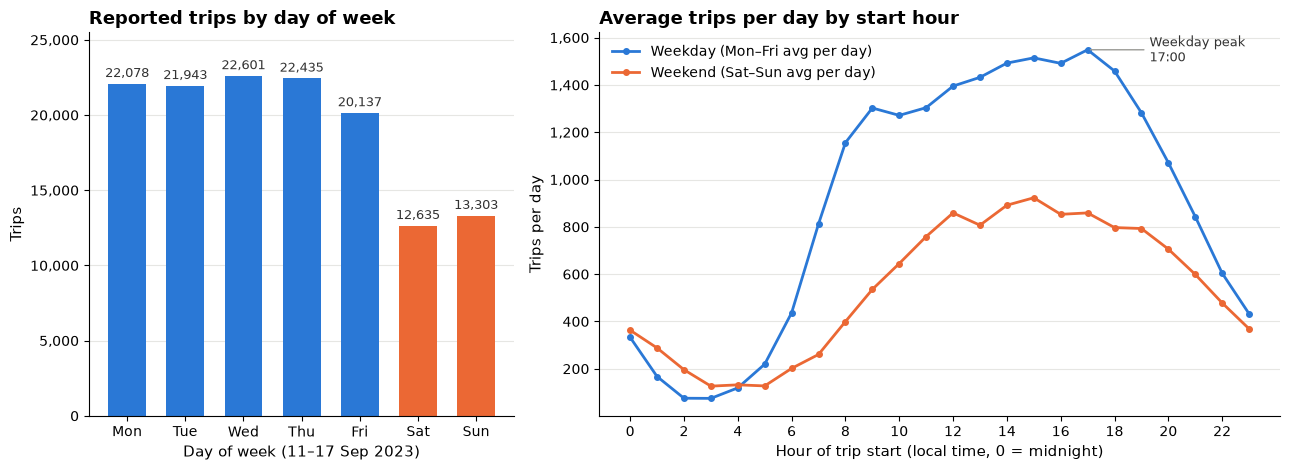

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})

# Left: trips by day of week
ax = axes[0]
cols_ = [BLUE] * 5 + [ORANGE] * 2
bars = ax.bar([d[:3] for d in days], by_day.trips, color=cols_, width=0.65)
for b, v in zip(bars, by_day.trips):
    ax.text(b.get_x() + b.get_width() / 2, v + 250, f"{v:,}", ha="center", va="bottom", fontsize=9, color="#333")
ax.set_title("Reported trips by day of week")
ax.set_xlabel("Day of week (11–17 Sep 2023)")
ax.set_ylabel("Trips")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_ylim(0, 25500)

# Right: average trips per day by start hour, weekday vs weekend
ax = axes[1]
ax.plot(hr.index, hr.weekday_per_day, color=BLUE, lw=2, marker="o", ms=4, label="Weekday (Mon–Fri avg per day)")
ax.plot(hr.index, hr.weekend_per_day, color=ORANGE, lw=2, marker="o", ms=4, label="Weekend (Sat–Sun avg per day)")
ax.set_title("Average trips per day by start hour")
ax.set_xlabel("Hour of trip start (local time, 0 = midnight)")
ax.set_ylabel("Trips per day")
ax.set_xticks(range(0, 24, 2))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_ylim(0, 1700)
ax.legend(frameon=False, loc="upper left")
ax.annotate("Weekday peak\n17:00", xy=(17, hr.weekday_per_day[17]), xytext=(19.3, 1500), fontsize=9, color="#333",
            arrowprops=dict(arrowstyle="-", color=GREY))

plt.tight_layout()
plt.savefig("figures/analysis/01_demand_by_day_and_hour.png", dpi=150, bbox_inches="tight")
plt.show()

# **Takeaway (Q1).** Demand is a weekday commuter-and-daytime pattern.
# - **Busiest day:** Wednesday (22,601 trips). Monday–Thursday are almost identical (about 22,000–22,600), and **Friday is a little lower** (20,137).
# - **Quietest day:** Saturday (12,635). A weekend day carries about **59% of the trips of a weekday** (12,969 vs 21,839 per day on average).
# - **Busiest hours:** weekday demand climbs sharply from 06:00, holds a plateau of roughly 1,300–1,500 trips per day from 09:00 to 18:59, and **peaks at 17:00** (about 1,550 trips per weekday). Across the whole week, 17:00, 15:00 and 14:00 are the three busiest hours.
# - **Quietest hours:** 02:00–04:00, with 03:00 the lowest hour (627 trips all week).
# - **Weekends** are flatter, peaking at about 920 trips per day around 15:00, with no sharp rush-hour peak. They are **busier than weekdays in the small hours** (00:00–03:59): 861–992 trips on Fri–Sun nights, against 464–706 on Mon–Thu.
#
# *Caveat:* the weekend profile rests on two days of one week, so treat the weekend averages as indicative.

# ## 4. Q2 — Where do trips start?
#
# Community areas are shown by their numeric code (naming them would need outside data, which is out of scope). "Revenue" is the sum of `trip_total`.

In [18]:
tot_trips, tot_rev = len(clean), clean.trip_total.sum()
area = (clean.dropna(subset=["pickup_community_area"])
        .assign(area=lambda x: x.pickup_community_area.astype(int))
        .groupby("area").agg(trips=("trip_id", "size"), revenue=("trip_total", "sum")))
area["trip_share_%"] = area.trips / tot_trips * 100
area["rev_share_%"] = area.revenue / tot_rev * 100
area["avg_total"] = area.revenue / area.trips

top_trips = area.sort_values("trips", ascending=False).head(10)
top_rev = area.sort_values("revenue", ascending=False).head(10)
print("n pickup areas:", len(area))
print("\nTop 10 by trip count:")
print(top_trips.round(2).to_string())
print(f"  -> top 10 = {top_trips.trips.sum()/tot_trips:.1%} of all trips")
print("\nTop 10 by total trip_total ($):")
print(top_rev.round(2).to_string())
print(f"  -> top 10 = {top_rev.revenue.sum()/tot_rev:.1%} of all revenue")
print("\nIn both top 10:", sorted(set(top_trips.index) & set(top_rev.index)))
print("Only in trips list:", sorted(set(top_trips.index) - set(top_rev.index)), "| only in revenue list:", sorted(set(top_rev.index) - set(top_trips.index)))

n pickup areas: 77

Top 10 by trip count:
      trips      revenue  trip_share_%  rev_share_%  avg_total
area                                                          
76    31533 1,727,203.86         23.33        42.95      54.77
8     28208   515,903.68         20.87        12.83      18.29
32    22058   419,518.50         16.32        10.43      19.02
28    11245   184,398.73          8.32         4.59      16.40
33     6675   171,966.51          4.94         4.28      25.76
56     5395   251,206.61          3.99         6.25      46.56
6      3924    77,708.57          2.90         1.93      19.80
7      2536    48,601.58          1.88         1.21      19.16
3      1915    39,353.81          1.42         0.98      20.55
77     1527    32,767.65          1.13         0.81      21.46
  -> top 10 = 85.1% of all trips

Top 10 by total trip_total ($):
      trips      revenue  trip_share_%  rev_share_%  avg_total
area                                                          
76    3153

In [19]:
no_area = clean.pickup_community_area.isna()
print(f"Trips with no pickup community area (clean base): {no_area.sum():,} = {no_area.mean():.2%} of trips; revenue ${clean.loc[no_area,'trip_total'].sum():,.0f} = {clean.loc[no_area,'trip_total'].sum()/tot_rev:.2%}")
print(f"Same share on the raw file (135,768 rows): {df.pickup_community_area.isna().sum():,} = {df.pickup_community_area.isna().mean():.2%}")
print(f"Avg trip_total: no-area ${clean.loc[no_area,'trip_total'].mean():.2f} vs with area ${clean.loc[~no_area,'trip_total'].mean():.2f}")
print(f"Median trip_miles (miles>0): no-area {clean.loc[no_area & (clean.trip_miles>0),'trip_miles'].median():.1f} vs with area {clean.loc[~no_area & (clean.trip_miles>0),'trip_miles'].median():.1f}")
print("No-area trips - dropoff area missing too:", f"{clean.loc[no_area,'dropoff_community_area'].isna().mean():.1%}")

Trips with no pickup community area (clean base): 3,736 = 2.76% of trips; revenue $128,786 = 3.20%
Same share on the raw file (135,768 rows): 3,815 = 2.81%
Avg trip_total: no-area $34.47 vs with area $29.62
Median trip_miles (miles>0): no-area 5.8 vs with area 4.5
No-area trips - dropoff area missing too: 78.4%


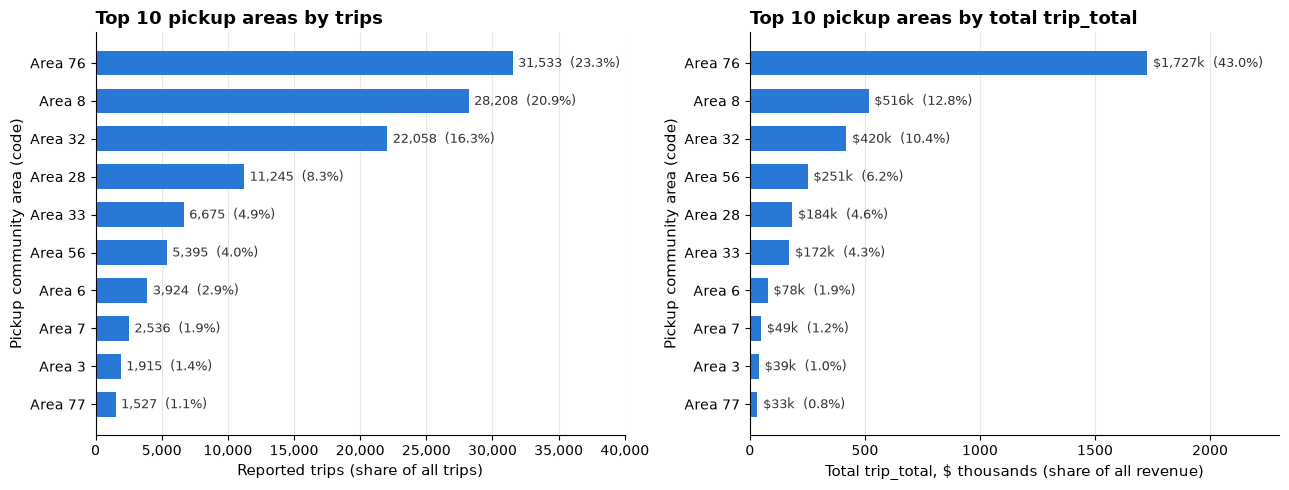

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)

ax = axes[0]
t = top_trips.iloc[::-1]
ax.barh([f"Area {a}" for a in t.index], t.trips, color=BLUE, height=0.65)
for y, (v, s) in enumerate(zip(t.trips, t["trip_share_%"])):
    ax.text(v + 400, y, f"{v:,}  ({s:.1f}%)", va="center", fontsize=9, color="#333")
ax.set_title("Top 10 pickup areas by trips")
ax.set_xlabel("Reported trips (share of all trips)")
ax.set_ylabel("Pickup community area (code)")
ax.set_xlim(0, 40000)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

ax = axes[1]
t = top_rev.iloc[::-1]
ax.barh([f"Area {a}" for a in t.index], t.revenue / 1000, color=BLUE, height=0.65)
for y, (v, s) in enumerate(zip(t.revenue / 1000, t["rev_share_%"])):
    ax.text(v + 25, y, f"${v:,.0f}k  ({s:.1f}%)", va="center", fontsize=9, color="#333")
ax.set_title("Top 10 pickup areas by total trip_total")
ax.set_xlabel("Total trip_total, $ thousands (share of all revenue)")
ax.set_ylabel("Pickup community area (code)")
ax.set_xlim(0, 2300)
ax.grid(axis="y", visible=False); ax.grid(axis="x")

plt.tight_layout()
plt.savefig("figures/analysis/02_top_pickup_areas.png", dpi=150, bbox_inches="tight")
plt.show()

# **Takeaway (Q2).**
# - Pickups are highly concentrated: **77 community areas have pickups, but the top 10 account for 85% of trips and 86% of revenue.** The same ten areas head both rankings, in a different order.
# - **Area 76 is #1 on both measures** (31,533 trips, 23% of all; $1.73M, 43% of revenue). **Area 8 and Area 32 follow on trips** (28,208 and 22,058).
# - **Revenue ranks differ from trip ranks because trips are not equal in value.** Areas 76 and 56 earn an average `trip_total` of $55 and $47 per trip, against $16–26 for the other top areas. As a result Area 56 ranks 4th on revenue but 6th on trips, and Area 28 falls from 4th on trips to 5th on revenue. (From general knowledge, not this data, I'd guess these two are airport areas; I haven't verified that.)
# - **2.8% of trips (3,736 after cleaning) have no pickup community area** (3.2% of revenue). They are mostly trips starting outside Chicago, per `dataset.md`, and their average total is higher ($34 vs $30). Most (78%) also have no dropoff area.

# ## 5. Q3 — How do riders pay and tip?
#
# - Average fare = mean of `fare` (the metered fare only); revenue = sum of `trip_total`.
# - Tip % = tips ÷ fare. I report it two ways: **aggregate** (sum of tips ÷ sum of fares) and **share of trips with a recorded tip**.
# - **Cash tips are generally not recorded**, so the tip figure for Cash is not comparable with the card types. The first table shows that `Prcard` (and `Unknown`) also record almost no tips (a tip on 5% / 0.2% of trips), so I treat them as *tips not recorded* too. The only like-for-like comparison is **Credit Card vs Mobile**.

In [21]:
pay = clean.groupby("payment_type").agg(
    trips=("trip_id", "size"),
    revenue=("trip_total", "sum"),
    avg_fare=("fare", "mean"),
    fare_sum=("fare", "sum"),
    tips_sum=("tips", "sum"),
    pct_trips_with_tip=("tips", lambda s: (s > 0).mean() * 100),
).sort_values("trips", ascending=False)
pay["trip_share_%"] = pay.trips / pay.trips.sum() * 100
pay["revenue_share_%"] = pay.revenue / pay.revenue.sum() * 100
pay["tip_%_of_fare (aggregate)"] = pay.tips_sum / pay.fare_sum * 100
out = pay[["trips", "trip_share_%", "revenue", "revenue_share_%", "avg_fare", "tips_sum", "tip_%_of_fare (aggregate)", "pct_trips_with_tip"]]
print(out.round(2).to_string())
print("\nTotal trips:", pay.trips.sum(), "| total revenue: $", round(pay.revenue.sum()))

              trips  trip_share_%      revenue  revenue_share_%  avg_fare   tips_sum  tip_%_of_fare (aggregate)  pct_trips_with_tip
payment_type                                                                                                                       
Credit Card   60158         44.52 2,396,109.88            59.59     28.74 383,603.32                      22.19               93.64
Cash          39554         29.27   784,952.17            19.52     18.18     949.10                       0.13                0.41
Mobile        18594         13.76   413,942.68            10.29     17.81  67,718.02                      20.45               92.69
Prcard        11961          8.85   307,513.93             7.65     25.43   2,266.24                       0.74                5.18
Unknown        4783          3.54   115,614.05             2.88     24.04      18.05                       0.02                0.15
No Charge        51          0.04     2,130.85             0.05     34.98   

In [22]:
# Like-for-like tip comparison: only payment types that record tips (Credit Card, Mobile)
card = clean[clean.payment_type.isin(["Credit Card", "Mobile"])].copy()
card["tip_pct"] = card.tips / card.fare * 100
cmp_ = card.groupby("payment_type").agg(
    trips=("trip_id", "size"),
    fare_sum=("fare", "sum"), tips_sum=("tips", "sum"),
    median_tip_pct_all_trips=("tip_pct", "median"),
    pct_with_tip=("tips", lambda s: (s > 0).mean() * 100),
    median_tip_pct_if_tipped=("tip_pct", lambda s: s[s > 0].median()),
)
cmp_["aggregate_tip_pct"] = cmp_.tips_sum / cmp_.fare_sum * 100
print("Payment types that record tips (Credit Card, Mobile):")
print(cmp_.drop(columns=["fare_sum", "tips_sum"]).round(2).to_string())
print(f"\nCredit Card + Mobile pooled: aggregate tip = {card.tips.sum()/card.fare.sum()*100:.1f}% of fare; {(card.tips>0).mean():.1%} of trips tipped")
print("Cash trips with tip > 0:", (clean[clean.payment_type == 'Cash'].tips > 0).sum(), "of", (clean.payment_type == 'Cash').sum())
print("All trips pooled (NOT like-for-like): aggregate tip =", round(clean.tips.sum() / clean.fare.sum() * 100, 1), "% of fare")
print("\nPer-trip tip % among tipped Credit Card/Mobile trips:")
print(card.loc[card.tips > 0, "tip_pct"].describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1).to_string())
print("\nTipped trips where tip > fare:", (card.tips > card.fare).sum(), "| tip > 2x fare:", (card.tips > 2 * card.fare).sum(), "| fare < $5 among those:", ((card.tips > 2 * card.fare) & (card.fare < 5)).sum())

Payment types that record tips (Credit Card, Mobile):
              trips  median_tip_pct_all_trips  pct_with_tip  median_tip_pct_if_tipped  aggregate_tip_pct
payment_type                                                                                            
Credit Card   60158                     22.63         93.64                     22.98              22.19
Mobile        18594                     22.22         92.69                     22.79              20.45

Credit Card + Mobile pooled: aggregate tip = 21.9% of fare; 93.4% of trips tipped
Cash trips with tip > 0: 162 of 39554
All trips pooled (NOT like-for-like): aggregate tip = 14.2 % of fare

Per-trip tip % among tipped Credit Card/Mobile trips:
count   73,566.00
mean        28.70
std        120.50
min          0.00
5%          11.40
25%         20.40
50%         22.90
75%         28.60
95%         51.60
99%        111.10
max     30,000.00

Tipped trips where tip > fare: 807 | tip > 2x fare: 413 | fare < $5 among those: 3

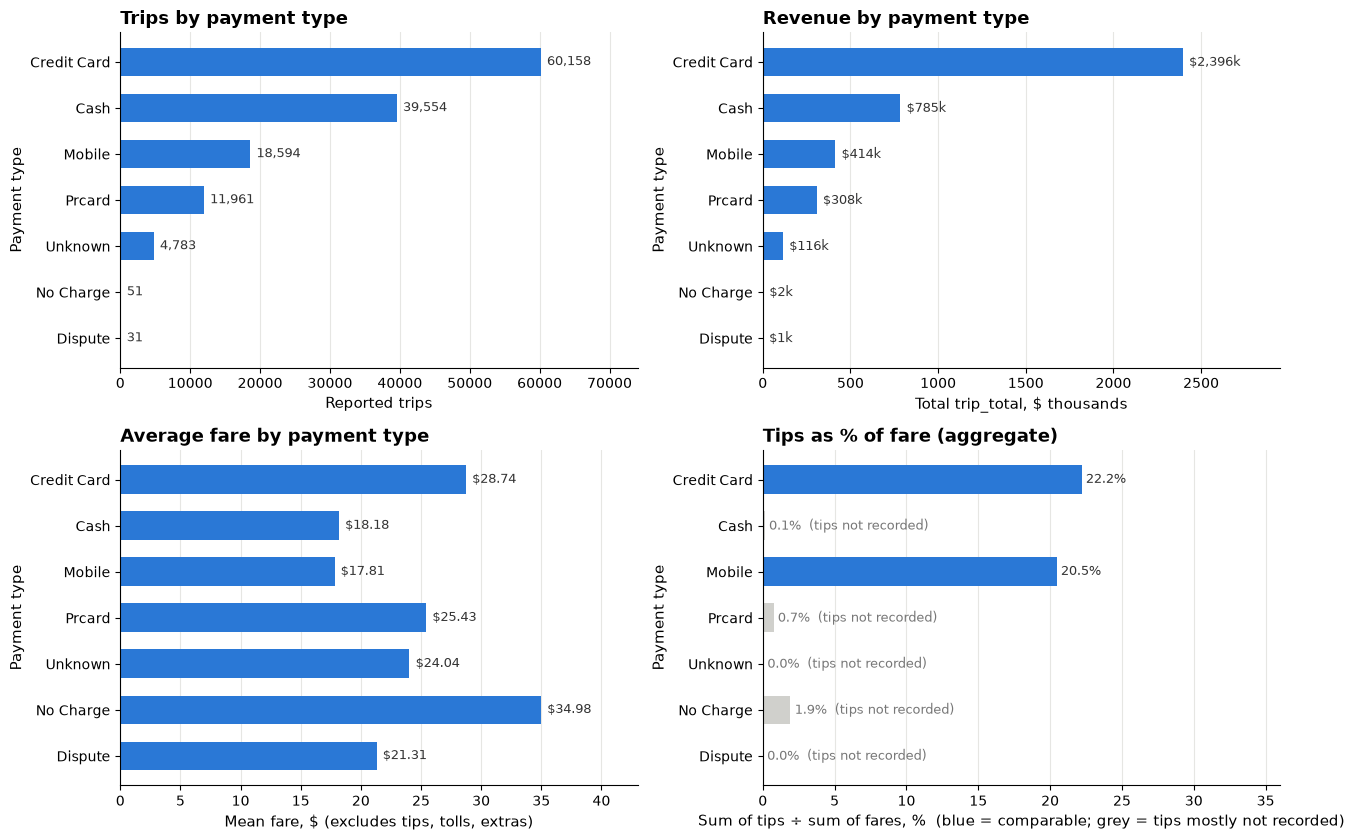

In [23]:
order = pay.index[::-1]   # largest at top in barh
labels = list(order)
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

def hbar(ax, vals, fmt, title, xlabel, xmax, colors=None):
    ax.barh(labels, vals, color=colors or BLUE, height=0.62)
    for y, v in enumerate(vals):
        ax.text(v + xmax * 0.012, y, fmt(v), va="center", fontsize=9, color="#333")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Payment type")
    ax.set_xlim(0, xmax)
    ax.grid(axis="y", visible=False); ax.grid(axis="x")

hbar(axes[0, 0], pay.loc[order, "trips"], lambda v: f"{v:,.0f}", "Trips by payment type", "Reported trips", 74000)
hbar(axes[0, 1], pay.loc[order, "revenue"] / 1000, lambda v: f"${v:,.0f}k", "Revenue by payment type", "Total trip_total, $ thousands", 2950)
hbar(axes[1, 0], pay.loc[order, "avg_fare"], lambda v: f"${v:.2f}", "Average fare by payment type", "Mean fare, $ (excludes tips, tolls, extras)", 43)

# Tip panel: only Credit Card and Mobile are like-for-like; others greyed and marked
tip = pay.loc[order, "tip_%_of_fare (aggregate)"]
comparable = [l in ("Credit Card", "Mobile") for l in labels]
ax = axes[1, 1]
ax.barh(labels, tip, color=[BLUE if c else "#d0d0cc" for c in comparable], height=0.62)
for y, (l, v, c) in enumerate(zip(labels, tip, comparable)):
    txt = f"{v:.1f}%" if c else f"{v:.1f}%  (tips not recorded)"
    ax.text(v + 0.3, y, txt, va="center", fontsize=9, color="#333" if c else "#777")
ax.set_title("Tips as % of fare (aggregate)")
ax.set_xlabel("Sum of tips ÷ sum of fares, %  (blue = comparable; grey = tips mostly not recorded)")
ax.set_ylabel("Payment type")
ax.set_xlim(0, 36)
ax.grid(axis="y", visible=False); ax.grid(axis="x")

axes[0, 0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.savefig("figures/analysis/03_payment_types.png", dpi=150, bbox_inches="tight")
plt.show()

# **Takeaway (Q3).**
# - **Credit Card is the main way to pay:** 44.5% of trips (60,158) and **59.6% of revenue** ($2.40M), with the highest average fare among the big types ($28.74). **Cash is second** (29.3% of trips, 19.5% of revenue) with a lower average fare ($18.18). Mobile is 13.8% of trips at a similarly low average fare ($17.81); Prcard 8.9%; Unknown 3.5%. No Charge and Dispute together are under 0.1% of trips.
# - **Tipping can only be compared between Credit Card and Mobile.** Both record tips electronically: about 93% of trips carry a tip, and the tip is **22.2% of fare on Credit Card and 20.5% on Mobile** (median per-trip tip about 22–23% on both).
# - **Cash, Prcard and Unknown record almost no tips** (tip on 0.4%, 5.2% and 0.2% of trips), so their tip percentages (0.0–0.7% of fare) say nothing about real tipping. Pooling all payment types gives 14.2% of fare, which is misleading for the same reason.
# - A few card tips are more than twice the fare, almost always on fares under $5. These do not affect the aggregate or median measures used here.

# ## 6. Q4 — Which companies carry the trips?
#
# Company names are the harmonised ones from the cleaning section. Share is of all 135,132 clean trips.

In [24]:
comp = clean.groupby("company_clean").agg(
    trips=("trip_id", "size"),
    revenue=("trip_total", "sum"),
    taxis=("taxi_id", "nunique"),
).sort_values("trips", ascending=False)
comp["share_of_trips_%"] = comp.trips / len(clean) * 100
comp["revenue_share_%"] = comp.revenue / clean.trip_total.sum() * 100
comp["trips_per_taxi"] = comp.trips / comp.taxis
comp["avg_trip_total"] = comp.revenue / comp.trips
top_comp = comp.head(10)
print(top_comp[["trips", "share_of_trips_%", "revenue", "revenue_share_%", "taxis", "trips_per_taxi", "avg_trip_total"]].round(2).to_string())
print(f"\nTop 10 combined: {top_comp.trips.sum():,} trips = {top_comp.trips.sum()/len(clean):.1%} of trips, {top_comp.revenue.sum()/clean.trip_total.sum():.1%} of revenue")
print(f"Other {len(comp)-10} companies: {comp.trips.iloc[10:].sum():,} trips = {comp.trips.iloc[10:].sum()/len(clean):.1%}")
print("Rank 11-12 for context:")
print(comp.iloc[10:12][["trips", "share_of_trips_%", "revenue", "taxis"]].round(2).to_string())

                              trips  share_of_trips_%    revenue  revenue_share_%  taxis  trips_per_taxi  avg_trip_total
company_clean                                                                                                           
Flash Cab                     25879             19.15 682,650.61            16.98    401           64.54           26.38
Taxi Affiliation Services     25629             18.97 721,597.11            17.95    457           56.08           28.16
Taxicab Insurance Agency Llc  16155             11.95 524,687.07            13.05    356           45.38           32.48
Sun Taxi                      15065             11.15 481,867.35            11.98    299           50.38           31.99
City Service                  13640             10.09 420,094.22            10.45    265           51.47           30.80
Chicago Independents           7935              5.87 254,252.20             6.32    189           41.98           32.04
5 Star Taxi                    6

In [25]:
# Checks: taxis shared across companies? distinct taxis overall vs sum of company taxis
n_co_per_taxi = clean.groupby("taxi_id").company_clean.nunique()
print("Distinct taxis overall:", clean.taxi_id.nunique(), "| sum of per-company distinct taxis:", comp.taxis.sum())
print("Taxis appearing under >1 company:", (n_co_per_taxi > 1).sum())
print("Distinct taxis across the top 10 (union):", clean[clean.company_clean.isin(top_comp.index)].taxi_id.nunique())
print("\nRanking effect of merging variants (raw names):")
raw_rank = clean.company.value_counts().head(11)
print(raw_rank.to_string())

Distinct taxis overall: 2656 | sum of per-company distinct taxis: 2659
Taxis appearing under >1 company: 3
Distinct taxis across the top 10 (union): 2414

Ranking effect of merging variants (raw names):
company
Flash Cab                         25879
Taxi Affiliation Services         25629
Sun Taxi                          15065
Taxicab Insurance Agency Llc      13800
City Service                      13640
Chicago Independents               7935
5 Star Taxi                        6097
Medallion Leasin                   4992
Globe Taxi                         4751
Blue Ribbon Taxi Association       4385
Star North Taxi Management Llc     2804


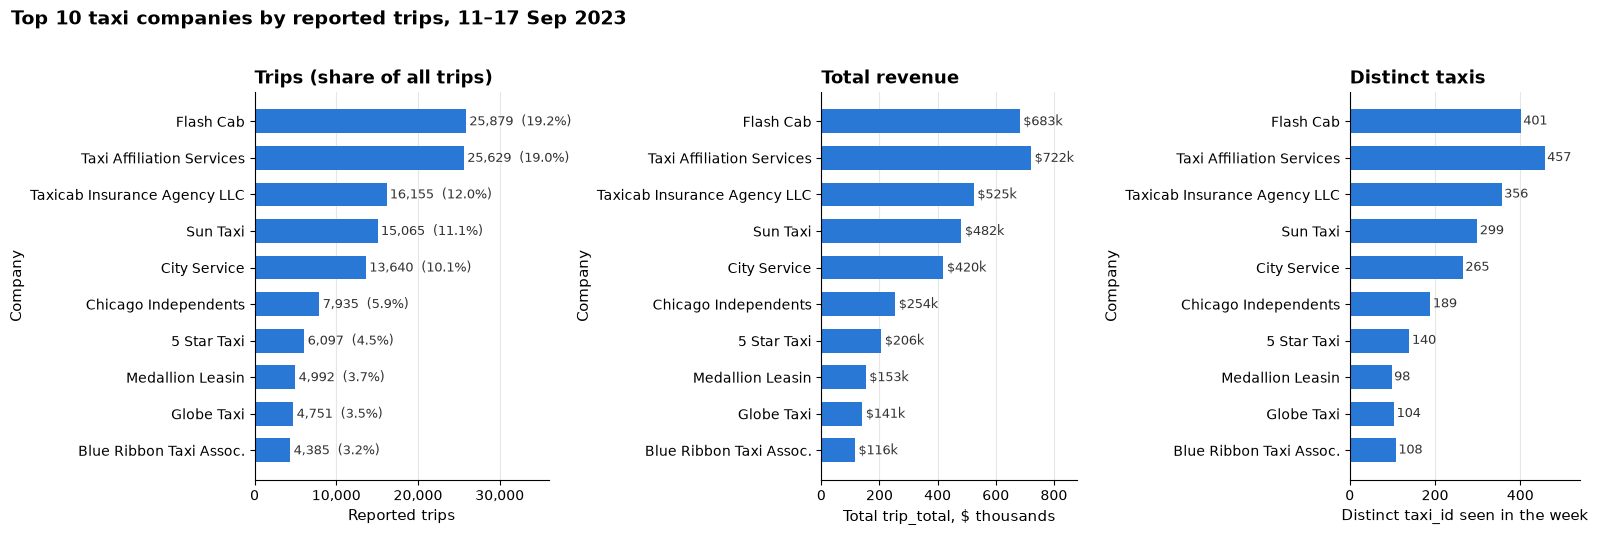

In [26]:
t = top_comp.iloc[::-1]
names = [n.replace(" Association", " Assoc.").replace(" Agency Llc", " Agency LLC") for n in t.index]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.15, 1, 0.9]})

ax = axes[0]
ax.barh(names, t.trips, color=BLUE, height=0.65)
for y, (v, s) in enumerate(zip(t.trips, t["share_of_trips_%"])):
    ax.text(v + 400, y, f"{v:,}  ({s:.1f}%)", va="center", fontsize=9, color="#333")
ax.set_title("Trips (share of all trips)"); ax.set_xlabel("Reported trips"); ax.set_ylabel("Company")
ax.set_xlim(0, 36000)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

ax = axes[1]
ax.barh(names, t.revenue / 1000, color=BLUE, height=0.65)
for y, v in enumerate(t.revenue / 1000):
    ax.text(v + 12, y, f"${v:,.0f}k", va="center", fontsize=9, color="#333")
ax.set_title("Total revenue"); ax.set_xlabel("Total trip_total, $ thousands"); ax.set_ylabel("Company")
ax.set_xlim(0, 880)

ax = axes[2]
ax.barh(names, t.taxis, color=BLUE, height=0.65)
for y, v in enumerate(t.taxis):
    ax.text(v + 6, y, f"{v:,}", va="center", fontsize=9, color="#333")
ax.set_title("Distinct taxis"); ax.set_xlabel("Distinct taxi_id seen in the week"); ax.set_ylabel("Company")
ax.set_xlim(0, 540)

for ax in axes:
    ax.grid(axis="y", visible=False); ax.grid(axis="x")
fig.suptitle("Top 10 taxi companies by reported trips, 11–17 Sep 2023", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("figures/analysis/04_top_companies.png", dpi=150, bbox_inches="tight")
plt.show()